In [5]:
import os

normal_path = "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/.cache/huggingface/download/Normal"
pd_path = "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/.cache/huggingface/download/PD"

print("Normal files:", len(os.listdir(normal_path)))
print("PD files:", len(os.listdir(pd_path)))

print("\nFirst 20 Normal filenames:")
print(os.listdir(normal_path)[:20])

print("\nFirst 20 PD filenames:")
print(os.listdir(pd_path)[:20])

Normal files: 5300
PD files: 4682

First 20 Normal filenames:
['non_1264.jpg.lock', 't1_fl3d_sag_p4_iso_1.0_018.png.lock', 'non_428.jpg.lock', 't1_fl3d_sag_p4_iso_1.0_035.png.lock', 'non_40.jpg.metadata', 'SWI_Images_050.png.lock', 'non_1045.jpg.lock', 'non_757.jpg.lock', 'non_263.jpg.metadata', 'non_265.jpg.lock', 'non_1482.jpg.metadata', 'non_92.jpg.lock', 'non_334.jpg.metadata', 'non_671.jpg.metadata', 'mIP_Images(SW)_051.png.metadata', 'non_1204.jpg.lock', 'non_664.jpg.lock', 'non_1768.jpg.metadata', 'non_1666.jpg.metadata', 'non_879.jpg.metadata']

First 20 PD filenames:
['aug_0_7979.jpeg.lock', 'aug_0_6551.jpeg.metadata', 'dReg_-_sDW_SSh_SENSE_013.png.metadata', 'aug_0_9419.jpeg.lock', 'sDW_SSh_038.png.metadata', 'aug_0_2367.jpeg.metadata', 'aug_0_2300.jpeg.metadata', 'aug_0_2652.jpeg.metadata', 'aug_0_458.jpeg.metadata', 'aug_0_7975.jpeg.metadata', 'aug_0_2887.jpeg.metadata', 'aug_0_7482.jpeg.metadata', 'sDW_SSh_044.png.metadata', 'aug_0_4321.jpeg.lock', 'aug_0_4246.jpeg.lock', 

In [7]:
import os

PARK_ROOT = "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI"

for root, dirs, files in os.walk(PARK_ROOT):

    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
    ]

    if image_files:
        print("\nActual image folder:")
        print(root)
        print("Number of images:", len(image_files))
        print("First 5:", image_files[:5])


Actual image folder:
/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/Normal
Number of images: 2649
First 5: ['non_798.jpg', 'mIP_Images(SW)_027.png', 'non_318.jpg', 'non_207.jpg', 'Pha_Images_059.png']

Actual image folder:
/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/PD
Number of images: 2341
First 5: ['aug_0_2956.jpeg', 'aug_0_3569.jpeg', 'aug_0_1462.jpeg', 'aug_0_7463.jpeg', 'aug_0_450.jpeg']


In [8]:
import os
import pandas as pd

class_paths = {
    "MildDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/MildDemented",

    "ModerateDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/ModerateDemented",

    "NonDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/NonDemented",

    "VeryMildDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/VeryMildDemented",

    "Normal":
        "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/Normal",

    "PD":
        "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/PD"
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

records = []

for class_name, folder in class_paths.items():

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        extension = os.path.splitext(filename)[1].lower()

        if os.path.isfile(filepath) and extension in IMAGE_EXTENSIONS:

            records.append({
                "filepath": filepath,
                "original_class": class_name
            })

df = pd.DataFrame(records)

print("Total actual image files:", len(df))
print()
print(df["original_class"].value_counts())

Total actual image files: 11390

original_class
NonDemented         3200
Normal              2649
PD                  2341
VeryMildDemented    2240
MildDemented         896
ModerateDemented      64
Name: count, dtype: int64


In [9]:
from PIL import Image

bad_images = []

for path in df["filepath"]:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        bad_images.append(path)

print("Corrupted/unreadable images:", len(bad_images))

Corrupted/unreadable images: 0


In [10]:
import os
import shutil

# Correct source folders
class_paths = {
    "MildDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/MildDemented",

    "ModerateDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/ModerateDemented",

    "NonDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/NonDemented",

    "VeryMildDemented":
        "/kaggle/input/datasets/akshayalella/dataset/Alzheimers_iee/Alzheimers_iee/Alzheimers_ieee/VeryMildDemented",

    "Normal":
        "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/Normal",

    "PD":
        "/kaggle/input/datasets/akshayalella/dataset/Parkinsons_MRI/PD"
}

# Output folder
OUTPUT_DIR = "/kaggle/working/6_Class_MRI_Dataset"

# Create class folders
for class_name in class_paths:
    os.makedirs(
        os.path.join(OUTPUT_DIR, class_name),
        exist_ok=True
    )

# Copy only actual image files
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

for class_name, source_folder in class_paths.items():

    destination_folder = os.path.join(
        OUTPUT_DIR,
        class_name
    )

    for filename in os.listdir(source_folder):

        if filename.lower().endswith(image_extensions):

            source = os.path.join(source_folder, filename)
            destination = os.path.join(destination_folder, filename)

            shutil.copy2(source, destination)

print("6-class dataset created successfully!")

6-class dataset created successfully!


In [11]:
zip_path = shutil.make_archive(
    "/kaggle/working/6_Class_MRI_Dataset",
    "zip",
    OUTPUT_DIR
)

print("ZIP file created:")
print(zip_path)

ZIP file created:
/kaggle/working/6_Class_MRI_Dataset.zip


In [12]:
import os

print(os.path.exists("/kaggle/working/6_Class_MRI_Dataset.zip"))
print(os.path.getsize("/kaggle/working/6_Class_MRI_Dataset.zip") / (1024**3), "GB")

True
0.0766155431047082 GB


In [27]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    # Read image
    image = tf.io.read_file(path)

    # Keep the current grayscale workflow
    image = tf.image.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    # Resize
    image = tf.image.resize(image, IMG_SIZE)

    # Normalize pixel values: 0–255 → 0–1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].values
    labels = dataframe["class_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df, shuffle=False)
test_ds = create_dataset(test_df, shuffle=False)

print("Datasets created successfully.")

Datasets created successfully.


In [28]:
images, labels = next(iter(train_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Minimum pixel:", tf.reduce_min(images).numpy())
print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 1)
Label shape: (32,)
Minimum pixel: 0.0
Maximum pixel: 1.0


TRAINING

In [15]:
DATASET_PATH = "/kaggle/working/6_Class_MRI_Dataset"

In [18]:
import os
import pandas as pd

class_names = [
    "MildDemented",
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented",
    "Normal",
    "PD"
]

records = []

for class_name in class_names:

    folder = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if os.path.isfile(filepath):
            records.append({
                "filepath": filepath,
                "original_class": class_name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print(df["original_class"].value_counts())

Total images: 11390
original_class
NonDemented         3200
Normal              2649
PD                  2341
VeryMildDemented    2240
MildDemented         896
ModerateDemented      64
Name: count, dtype: int64


In [20]:
label_map = {
    "MildDemented": 0,
    "ModerateDemented": 1,
    "NonDemented": 2,
    "VeryMildDemented": 3,
    "Normal": 4,
    "PD": 5
}

df["class_id"] = df["original_class"].map(label_map)

In [21]:
from sklearn.model_selection import train_test_split

# 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_id"],
    random_state=42
)

# Split remaining 30% into 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_id"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 7973
Validation: 1708
Test: 1709


In [22]:
print("TRAIN")
print(train_df["original_class"].value_counts())
print()

print("VALIDATION")
print(val_df["original_class"].value_counts())
print()

print("TEST")
print(test_df["original_class"].value_counts())

TRAIN
original_class
NonDemented         2240
Normal              1854
PD                  1639
VeryMildDemented    1568
MildDemented         627
ModerateDemented      45
Name: count, dtype: int64

VALIDATION
original_class
NonDemented         480
Normal              397
PD                  351
VeryMildDemented    336
MildDemented        134
ModerateDemented     10
Name: count, dtype: int64

TEST
original_class
NonDemented         480
Normal              398
PD                  351
VeryMildDemented    336
MildDemented        135
ModerateDemented      9
Name: count, dtype: int64


BUIDING CNN

In [23]:
import tensorflow as tf

NUM_CLASSES = 6

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(256, (3, 3), activation="relu", padding="same"),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

I0000 00:00:1790446370.415813      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790446370.419194      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,510 (1.61 MB)

 Trainable params: 421,510 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["class_id"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["class_id"]
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
for class_id, weight in class_weights.items():
    print(
        class_id,
        class_names[class_id],
        ":", round(weight, 4)
    )

Class weights:
0 MildDemented : 2.1194
1 ModerateDemented : 29.5296
2 NonDemented : 0.5932
3 VeryMildDemented : 0.8475
4 Normal : 0.7167
5 PD : 0.8108


In [25]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [29]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights
)

Epoch 1/20
  3/250 ━━━━━━━━━━━━━━━━━━━━ 13s 54ms/step - accuracy: 0.2083 - loss: 1.5341

I0000 00:00:1790446541.440051     204 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


248/250 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.2964 - loss: 1.6611

2026-09-26 18:15:55.103007: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-26 18:15:55.245968: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


250/250 ━━━━━━━━━━━━━━━━━━━━ 29s 76ms/step - accuracy: 0.3474 - loss: 1.5789 - val_accuracy: 0.2119 - val_loss: 1.3485
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step - accuracy: 0.3595 - loss: 1.4232 - val_accuracy: 0.4778 - val_loss: 1.3188
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step - accuracy: 0.4011 - loss: 1.3776 - val_accuracy: 0.5504 - val_loss: 1.2304
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - accuracy: 0.4160 - loss: 1.3501 - val_accuracy: 0.4848 - val_loss: 1.2562
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - accuracy: 0.4757 - loss: 1.2323 - val_accuracy: 0.6165 - val_loss: 0.9131
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - accuracy: 0.5777 - loss: 1.0756 - val_accuracy: 0.6710 - val_loss: 0.7559
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - accuracy: 0.6034 - loss: 1.0353 - val_accuracy: 0.6938 - val_loss: 0.7610
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - accuracy: 0.5917 - loss: 0.9763 - val_accurac

In [30]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.6712 - loss: 0.6298
Test Loss: 0.6298245787620544
Test Accuracy: 0.6711527109146118


In [31]:
from sklearn.metrics import classification_report
import numpy as np

# Get predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

                  precision    recall  f1-score   support

    MildDemented     0.2691    0.4963    0.3490       135
ModerateDemented     0.0413    0.5556    0.0769         9
     NonDemented     0.7622    0.4542    0.5692       480
VeryMildDemented     0.3980    0.3601    0.3781       336
          Normal     0.9730    0.9950    0.9839       398
              PD     0.9942    0.9687    0.9812       351

        accuracy                         0.6712      1709
       macro avg     0.5730    0.6383    0.5564      1709
    weighted avg     0.7446    0.6712    0.6928      1709



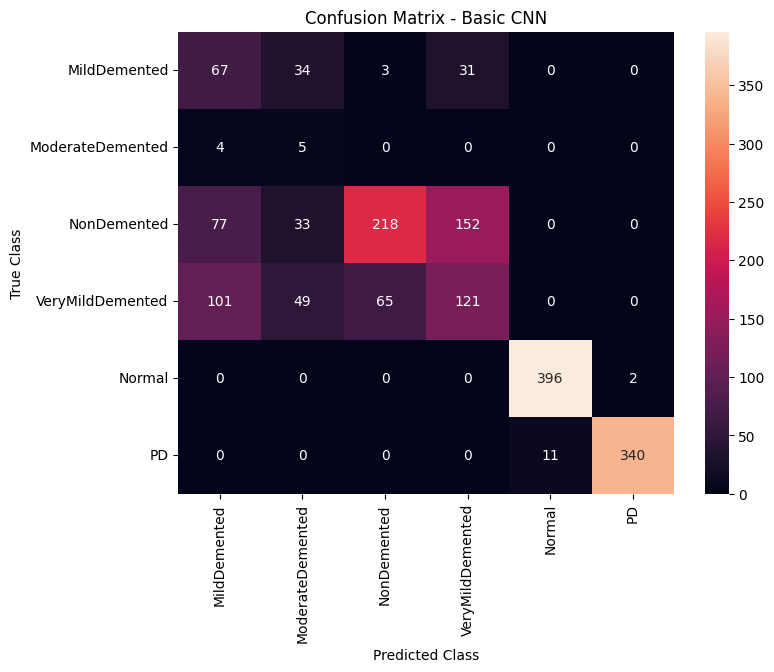

In [32]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix - Basic CNN")
plt.show()